In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
import os
import sys
singlecol = 3.5
plt.rcParams.update({'font.size': 12})
#plt.rcParams.update({'font.sans-serif': 'Helvetica'})
#plt.rcParams['font.family'] = 'dejavu'
plt.rcParams.update({'lines.linewidth':0.5})
plt.rcParams.update({'axes.linewidth':0.5})
plt.rcParams.update({'lines.markersize':2})
plt.rcParams.update({'savefig.dpi':200})
plt.rcParams.update({'legend.fontsize': 10})

In [4]:
def load_cfg(file_path):
    atom_data_lines = []
    in_atom_data_section = False

    with open(file_path, 'r') as file:
        for line in file:
            if line.startswith(" AtomData:"):
                in_atom_data_section = True
                continue
            if line.startswith(" Feature"):
                in_atom_data_section = False
            
            if in_atom_data_section:
                # Split the line by whitespace
                parts = line.split()
                
                # Convert relevant columns to numbers
                id_num = int(parts[0])
                type_num = int(parts[1])
                cartes_x = float(parts[2])
                cartes_y = float(parts[3])
                cartes_z = float(parts[4])
                nbh_grades = float(parts[5])
                
                # Store as a tuple or list
                atom_data_lines.append([id_num, type_num, cartes_x, cartes_y, cartes_z, nbh_grades])
    
    return atom_data_lines

In [5]:
def load_dump(filename):
    with open(filename, 'r') as file:
        lines = file.readlines()[9:]
    # Split each line into separate numbers
    numbers = []
    for line in lines:
        line_numbers = [float(num) for num in line.split()]  # Assuming numbers are floats
        numbers.append(line_numbers)
    
    # Convert the list of lists into a NumPy array
    return np.array(numbers)

In [6]:
def load_num(filename):
    with open(filename, 'r') as file:
        lines = file.readlines()
    # Split each line into separate numbers
    numbers = []
    for line in lines:
        line_numbers = [float(num) for num in line.split()]  # Assuming numbers are floats
        numbers.append(line_numbers)
    
    # Convert the list of lists into a NumPy array
    return np.array(numbers)

In [42]:
import numpy as np

def convert_lammps_dump_to_cfg(dump_file, cfg_file):
    with open(dump_file, 'r') as f_in, open(cfg_file, 'w') as f_out:
        # Read and parse the dump file
        lines = f_in.readlines()
        
        # Example header parsing (you may need to adjust depending on your dump format)
        num_atoms = int(lines[3].strip())  # Assuming num_atoms is on the fourth line
        
        # Write the CFG file header
        f_out.write("BEGIN_CFG\n")
        f_out.write("Size\n")
        f_out.write(f"{num_atoms}\n")
        f_out.write("AtomData:  id type       cartes_x      cartes_y      cartes_z\n")
        
        # Loop through each atom data line
        for i in range(9, 9 + num_atoms):  # Assuming atom data starts from line 10
            line = lines[i].split()
            atom_id = i-8
            atom_type = int(line[1])-1  # Assuming atom type is the second column
            cartes_x = float(line[2])
            cartes_y = float(line[3])
            cartes_z = float(line[4])
            
            # Write the atom data to the CFG file
            f_out.write(f" {atom_id:5d} {atom_type:5d} {cartes_x:15.6f} {cartes_y:15.6f} {cartes_z:15.6f}\n")
        f_out.write("END_CFG\n")

# Example usage
dump_file = './relax_18.dump'
cfg_file = 'relax_C_1.cfg'
convert_lammps_dump_to_cfg(dump_file, cfg_file)

In [6]:
before = []
after = []
fix_num = []
for i in range(8):
    before_file = f'cal_before.cfg{i}.0'
    after_file = f'cal_after.cfg{i}.0'
    fix_atom = f'fix_atom_num.txt{i}'
    before.append(load_cfg(before_file))
    after.append(load_cfg(after_file))
    fix_num.append(load_num(fix_atom))

FileNotFoundError: [Errno 2] No such file or directory: 'cal_before.cfg0.0'

In [7]:
before[0][:,1]

IndexError: list index out of range

## Number of atoms

In [14]:
data1 = load_cfg('./R_18.cfg')

In [13]:
data2 = load_dump('./relax_18.dump')

In [24]:
counts[0]

array([24.,  4.,  4., 24.,  8.])

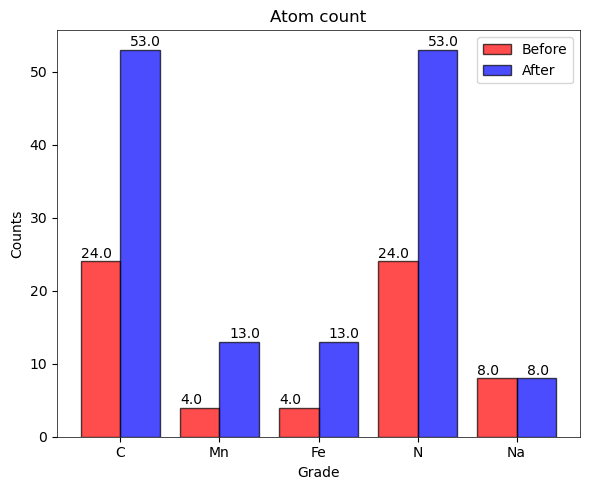

In [27]:
fig = plt.figure(figsize=(6,5))

bin_edges = np.arange(1, 7, 1)  # bins from -10 to 20
i=0
# Plotting the first histogram
counts, edges, bars = plt.hist([data1[:,1],data2[:,1]+1],
                               bins=bin_edges, alpha=0.7, color=['red','blue'], 
                               edgecolor='black', label = ['Before','After'])
for j in range(len(counts[0])):
   x = j+1.1
   y = counts[0][j] + 0.5
   plt.text(x, y, counts[0][j])

for j in range(len(counts[1])):
   x = j+1.6
   y = counts[1][j] + 0.5
   plt.text(x, y, counts[1][j])


tick_labels = ['C', 'Mn', 'Fe', 'N', 'Na']
tick_positions = (bin_edges[:-1] + bin_edges[1:]) / 2  # position the labels at the center of each bin
plt.xticks(tick_positions, tick_labels)

plt.title(f'Atom count')
plt.xlabel('Grade')
plt.ylabel('Counts')
plt.legend()

plt.tight_layout()
plt.show()

In [46]:
fix_num

[array([[86.]]),
 array([[80.]]),
 array([[75.]]),
 array([[81.]]),
 array([[80.]]),
 array([[78.]]),
 array([[79.]]),
 array([[78.]])]

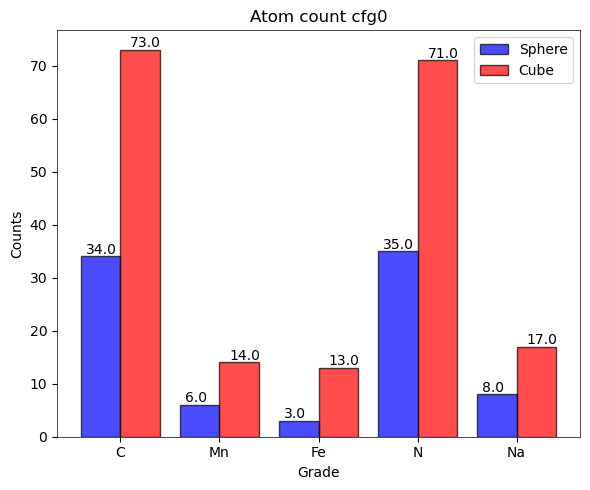

In [39]:
fig = plt.figure(figsize=(6,5))

bin_edges = np.arange(0, 6, 1)  # bins from -10 to 20
i=0
# Plotting the first histogram
counts, edges, bars = plt.hist([before[i][:int(fix_num[i][0,0]),1], before[i][:,1]],
                               bins=bin_edges, alpha=0.7, color=['blue','red'], 
                               edgecolor='black',label = ['Sphere','Cube'])
for j in range(len(counts[0])):
   x = j+0.15
   y = counts[0][j] + 0.5
   plt.text(x, y, counts[0][j])

for j in range(len(counts[1])):
   x = j+0.6
   y = counts[1][j] + 0.5
   plt.text(x, y, counts[1][j])

tick_labels = ['C', 'Mn', 'Fe', 'N', 'Na']
tick_positions = (bin_edges[:-1] + bin_edges[1:]) / 2  # position the labels at the center of each bin
plt.xticks(tick_positions, tick_labels)

plt.title(f'Atom count cfg{i}')
plt.xlabel('Grade')
plt.ylabel('Counts')
plt.legend()

plt.tight_layout()
plt.show()

## Grade Analysis

In [9]:
def load_selected(file_path):
    atom_data_lines = []
    in_atom_data_section = False

    with open(file_path, 'r') as file:
        for line in file:
            if line.startswith(" AtomData:"):
                in_atom_data_section = True
                continue
            if line.startswith(" Feature"):
                in_atom_data_section = False
            
            if in_atom_data_section:
                # Split the line by whitespace
                parts = line.split()
                
                # Convert relevant columns to numbers
                id_num = int(parts[0])
                type_num = int(parts[1])
                cartes_x = float(parts[2])
                cartes_y = float(parts[3])
                cartes_z = float(parts[4])
                nbh_grades = float(parts[6])
                
                # Store as a tuple or list
                atom_data_lines.append([id_num, type_num, cartes_x, cartes_y, cartes_z, nbh_grades])
    
    return atom_data_lines

In [66]:
cut = np.array(load_selected('./selected_18.txt'))
before = np.array(load_cfg('./cal_R_18.cfg.0'))
after = np.array(load_cfg('./cal_relax_18.cfg.0'))

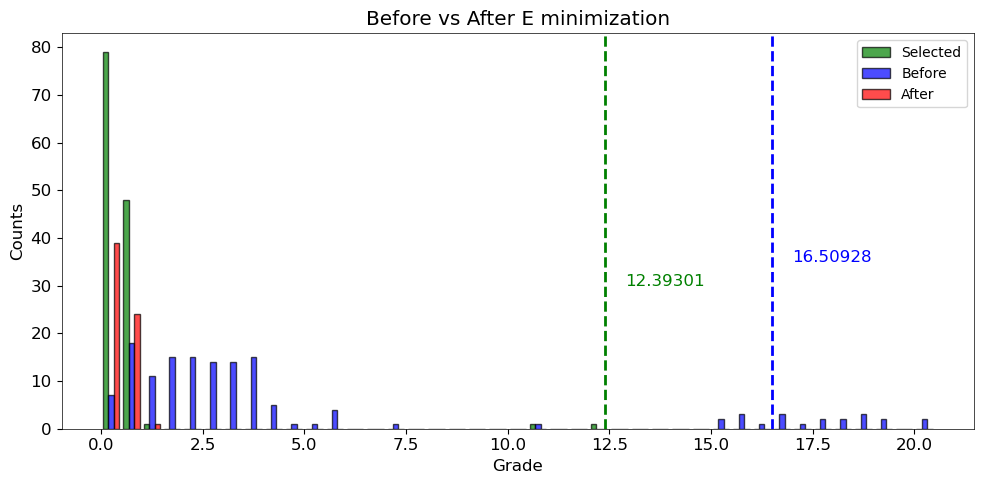

In [67]:
#for i in range(8):
fig = plt.figure(figsize=(10,5))

bin_edges = np.arange(0, 21, 0.5)  # bins from -10 to 20
bin_edges = np.append(bin_edges, np.inf)  # add a bin for values > 20

# Plotting the first histogram
plt.hist([cut[:,5], np.clip(before[:,5],0,20), np.clip(after[:,5],0,20)], 
             bins=bin_edges, alpha=0.7, color=['green','blue','red'], edgecolor='black',label = ['Selected','Before','After'])

plt.axvline(x=cut[:,5].max(), color='green', linestyle='--', linewidth=2)
plt.text(x=cut[:,5].max()+0.5, y=30, color='g',s=f'{cut[:,5].max()}')

plt.axvline(x=before[0,5], color='blue', linestyle='--', linewidth=2)
plt.text(x=before[0,5]+0.5, y=35, color='blue', s=f'{before[0,5]}')

plt.title(f'Before vs After E minimization')
plt.xlabel('Grade')
plt.ylabel('Counts')
plt.legend()

plt.tight_layout()
plt.show()

### Grade and distance correlation

In [68]:
origin = [0,0,0]
distance_before = np.linalg.norm(before[:,2:5]- origin, axis=1)
origin = [0.260525,      0.517179,      4.343140]
distance_after = np.linalg.norm(after[:,2:5]- origin, axis=1)

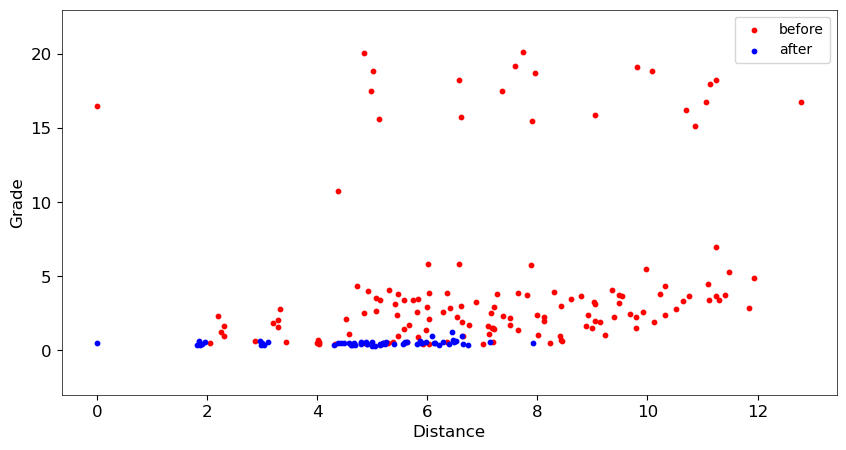

In [69]:
fig = plt.figure(figsize=(10,5))

plt.scatter(distance_before, before[:,5], color='r', label='before', s=10)
plt.scatter(distance_after, after[:,5], color='blue', label='after', s=10)
plt.ylim(-3,23)
plt.xlabel('Distance')
plt.ylabel('Grade')
plt.legend()

In [43]:
before = np.array(load_cfg('./cal_C_1.cfg.0'))
after = np.array(load_cfg('./cal_relax_C_1.cfg.0'))

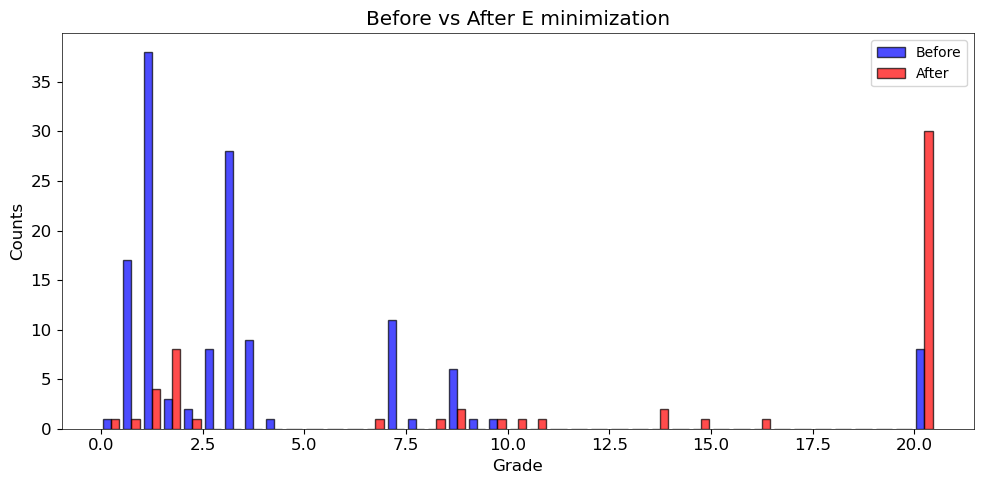

In [46]:
#for i in range(8):
fig = plt.figure(figsize=(10,5))

bin_edges = np.arange(0, 21, 0.5)  # bins from -10 to 20
bin_edges = np.append(bin_edges, np.inf)  # add a bin for values > 20

# Plotting the first histogram
plt.hist([np.clip(before[:,5],0,20), np.clip(after[:,5],0,20)], 
             bins=bin_edges, alpha=0.7, color=['blue','red'], edgecolor='black',label = ['Before','After'])
#plt.axvline(x=cut[:,5].max(), color='red', linestyle='--', linewidth=2)
#plt.text(x=cut[:,5].max()+1, y=30, s=f'Grade = {cut[:,5].max()}')
plt.title(f'Before vs After E minimization')
plt.xlabel('Grade')
plt.ylabel('Counts')
plt.legend()

plt.tight_layout()
plt.show()

In [48]:
origin = [0,0,0]
distance_before = np.linalg.norm(before[:,2:5]- origin, axis=1)
distance_after = np.linalg.norm(after[:,2:5]- origin, axis=1)

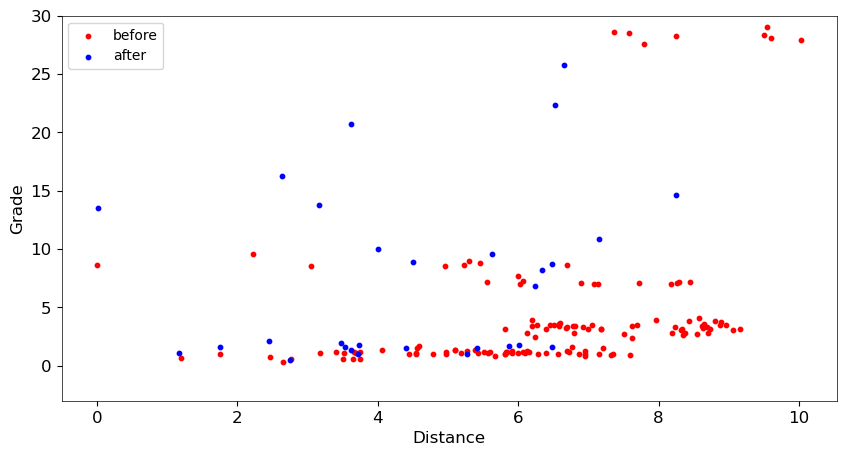

In [49]:
fig = plt.figure(figsize=(10,5))

plt.scatter(distance_before, before[:,5], color='r', label='before', s=10)
plt.scatter(distance_after, after[:,5], color='blue', label='after', s=10)
plt.ylim(-3,30)
plt.xlabel('Distance')
plt.ylabel('Grade')
plt.legend()

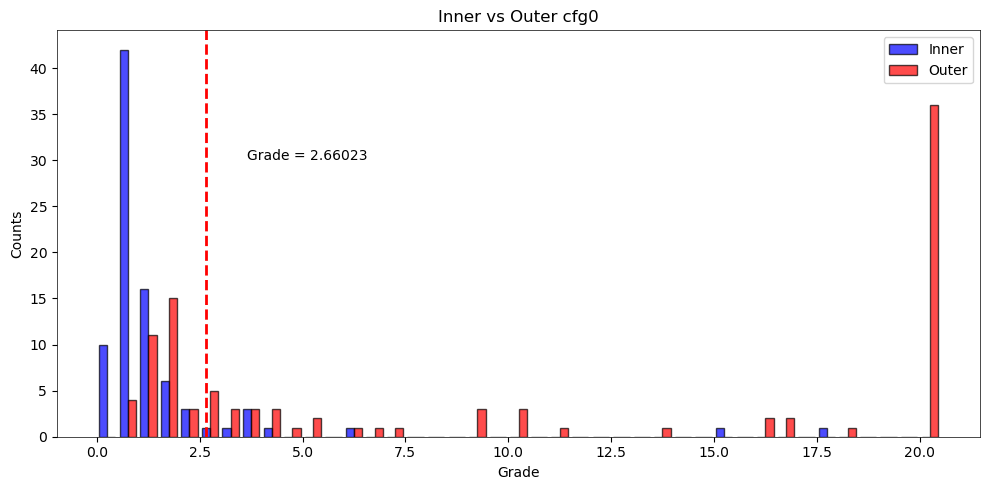

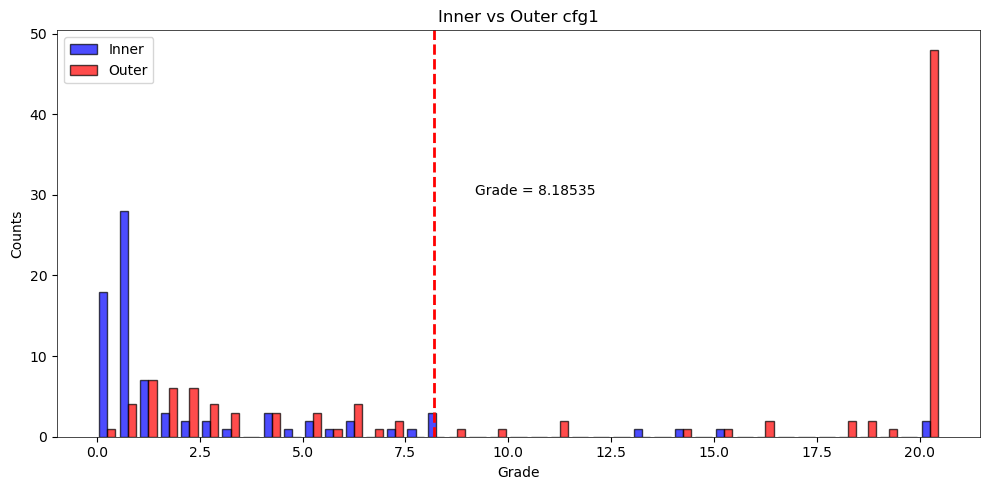

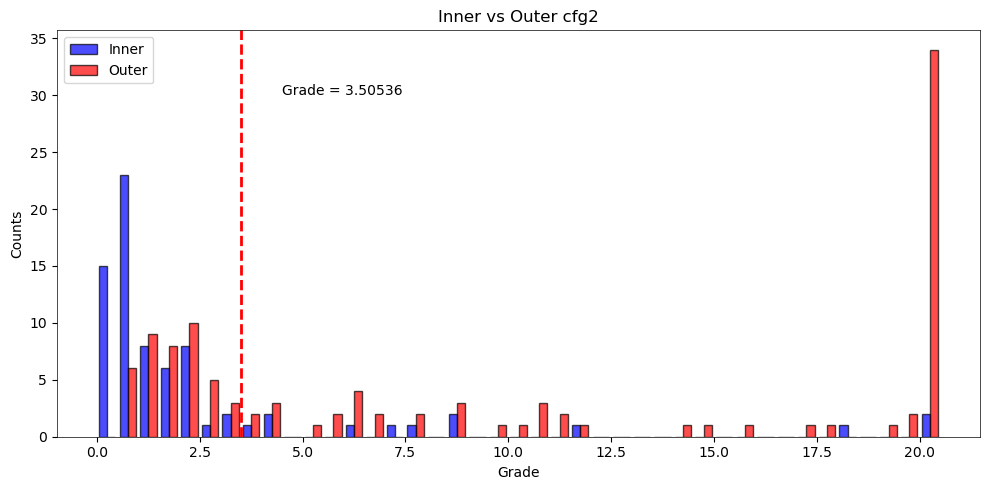

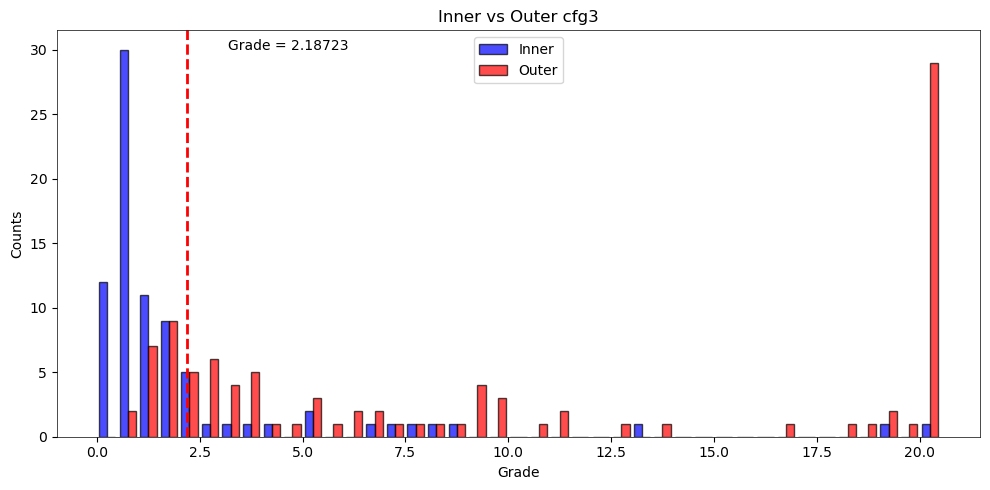

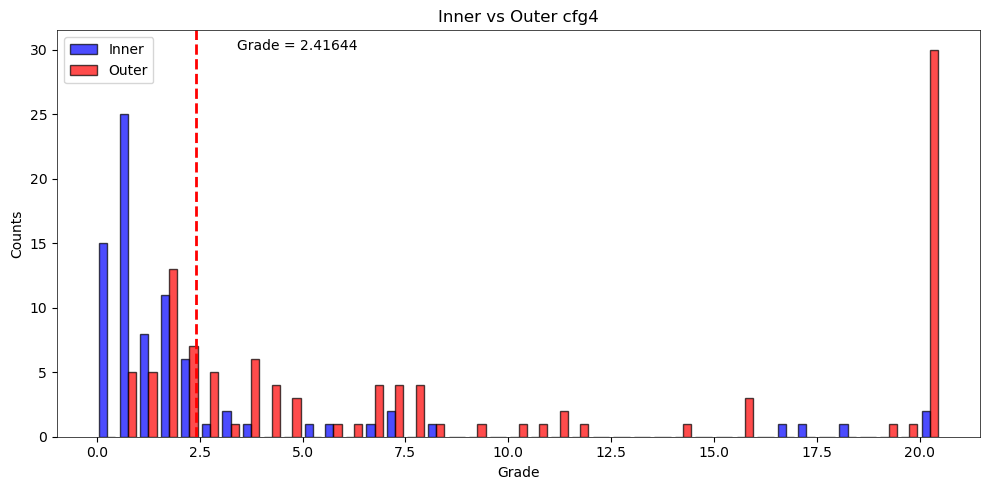

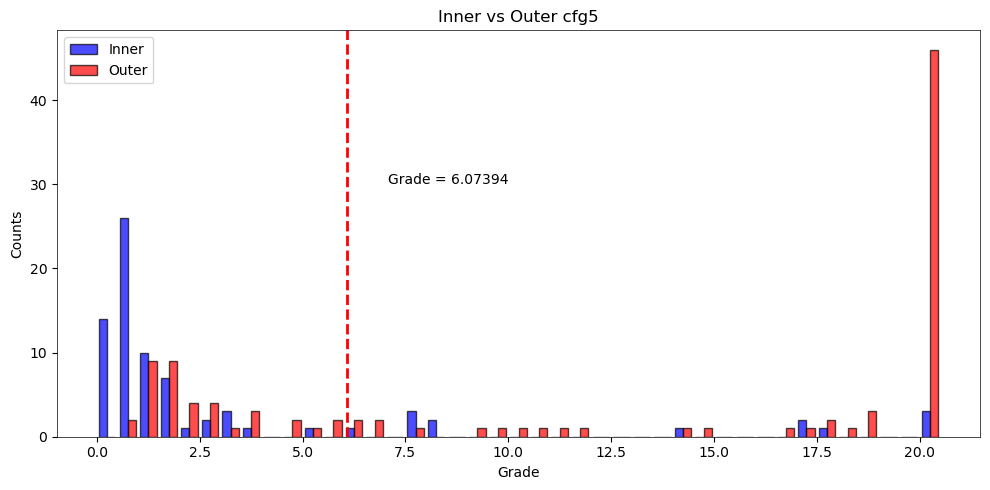

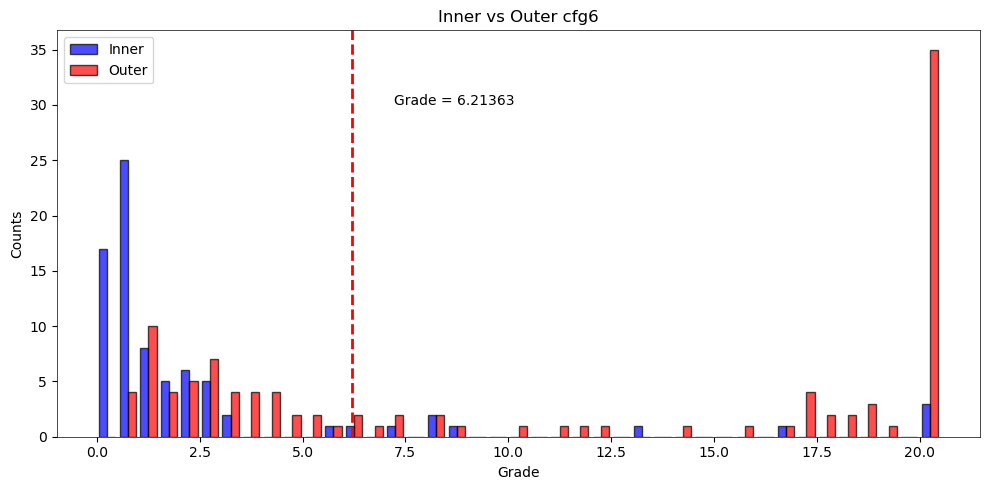

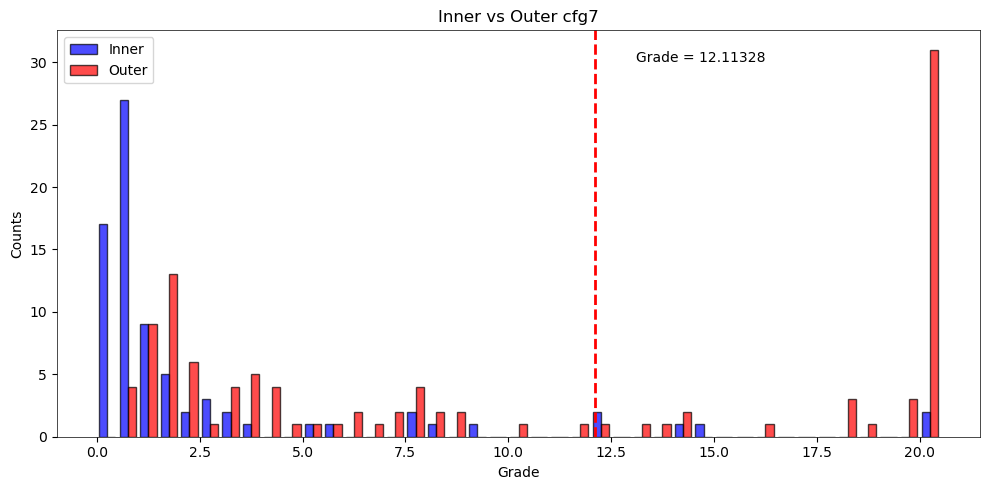

In [45]:
for i in range(8):
    fig = plt.figure(figsize=(10,5))
    
    bin_edges = np.arange(0, 21, 0.5)  # bins from -10 to 20
    bin_edges = np.append(bin_edges, np.inf)  # add a bin for values > 20
    
    # Plotting the first histogram
    plt.hist([np.clip(before[i][:int(fix_num[i][0,0]),5],0,20),np.clip(before[i][int(fix_num[i][0,0]):,5],0,20)], 
                 bins=bin_edges, alpha=0.7, color=['blue','red'], edgecolor='black',label = ['Inner','Outer'])
    plt.axvline(x=before[i][0,5], color='red', linestyle='--', linewidth=2)
    plt.text(x=before[i][0,5]+1, y=30, s=f'Grade = {before[i][0,5]}')
    plt.title(f'Inner vs Outer cfg{i}')
    plt.xlabel('Grade')
    plt.ylabel('Counts')
    plt.legend()
    
    plt.tight_layout()